# Escenarios y recomendación A013

**Pregunta:** ¿qué política de pedidos equilibra contribución y servicio cuando
la demanda y los costes no coinciden con el escenario central?

Se mantiene el mismo plan inicial en los tres escenarios. Las revisiones utilizan
únicamente ventas observables y disponibilidad, con tres meses de plazo. El
objetivo es maximizar la contribución media central con servicio anual esperado
del 95 % en los segmentos viables; los escenarios no tienen probabilidades.
La extensión hasta junio de A014 es una sensibilidad de continuidad, no una
previsión validada. Véase `../docs/plan-revision-modelo.md`, decisiones D10–D23.


In [1]:
from pathlib import Path
from types import SimpleNamespace
import json
import platform
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

plt.style.use("../config/graficos.mplstyle")
TABLAS = Path("../results/escenarios/tablas")
FIGURAS = Path("../results/escenarios/figuras")
TABLAS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)
ORDEN_ESC = ["pesimista", "central", "optimista"]
COLORES = {"pesimista": "#D55E00", "central": "#0072B2", "optimista": "#009E73"}
TRAZOS = {"pesimista": ":", "central": "--", "optimista": "-."}
SEMILLA, N_PILOTO, N_REP = 42, 200, 1000
HORIZONTE, HORIZONTE_PLAN = 18, 21
OBJETIVO_SERVICIO = 0.95


def cargar_api(ruta):
    """Carga solo definiciones etiquetadas, sin ejecutar análisis ni exportaciones."""
    contenido = json.loads(Path(ruta).read_text(encoding="utf-8"))
    entorno = {"__name__": Path(ruta).stem + "_api"}
    celdas = [c for c in contenido["cells"]
              if c["cell_type"] == "code" and "api" in c["metadata"].get("tags", [])]
    if not celdas:
        raise ValueError(f"No hay API revisada en {ruta}; ejecutar la revisión primero")
    for celda in celdas:
        exec(compile("".join(celda["source"]), str(ruta), "exec"), entorno)
    return SimpleNamespace(**entorno)


def guardar(tabla, nombre):
    tabla.to_csv(TABLAS / f"{nombre}.csv", index=False)


def figura(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURAS / f"{nombre}.svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)


def numero(valor, decimales=0):
    return f"{valor:,.{decimales}f}".replace(",", "_").replace(".", ",").replace("_", ".")


api_demanda = cargar_api("demanda.ipynb")
api_sim = cargar_api("simulacion.ipynb")
BASE = api_demanda.preparar_prevision_revision()
dd = BASE["datos"]
SEGMENTOS = list(api_sim.SEGMENTOS)
ficha = dd["segmentos"].set_index("segmento").loc[SEGMENTOS]
SIGMA3 = np.asarray(BASE["sigma3_rel"].reindex(SEGMENTOS), dtype=float)
SD_LOG = np.asarray(BASE["sd_log"].reindex(SEGMENTOS), dtype=float)
PHI, RHO = float(BASE["phi"]), float(BASE["rho"])
assert np.isfinite(SIGMA3).all() and np.isfinite(SD_LOG).all()


## 1. Supuestos y prolongación operativa

Los efectos estimados de economía, ayudas, producto, turismo y devolución del
adelanto se calculan en la API de `demanda.ipynb`, sin volver al modelo histórico.
El adelanto de A012 se descuenta una sola vez, distribuido en uno, tres o seis
meses. La simulación añade aquí los costes y las restricciones físicas.

No hay datos de combustible, divisa ni base aduanera para identificar elasticidades
o tipos efectivos. Se usan **pruebas de estrés explícitas**: efecto residual del
combustible de ±3 % sobre demanda, coste arancelario adicional de 500 €/importación
nueva en el pesimista y ahorro cambiario de 250 €/importación nueva en el optimista.
No son estimaciones históricas ni porcentajes sobre el PVP. Se estudian también
valores cero y dobles, manteniendo los otros factores fijos. El efecto de combustible
representa solo el efecto adicional no recogido por la trayectoria macroeconómica.


In [2]:
DEM_12 = {
    nombre: api_demanda.prever_escenario_revision(BASE, nombre)
    .reindex(columns=SEGMENTOS).to_numpy(dtype=float)
    for nombre in ORDEN_ESC
}
DEM_BRUTA = {nombre: api_demanda.prever_escenario_revision(BASE, nombre, {"sin_ledger": True})
             .reindex(columns=SEGMENTOS).to_numpy(dtype=float) for nombre in ORDEN_ESC}
assert np.allclose(DEM_12["central"], BASE["prevision"][SEGMENTOS].to_numpy())
COMBUSTIBLE = {"pesimista": -0.03, "central": 0.0, "optimista": 0.03}
PARAMETROS = {
    "pesimista": {"prima_co2": True, "arancel_eur": np.full(7, 500.0),
                  "cambio_eur": np.zeros(7), "suministro": ("MSUV", 3),
                  "frenar_no_rentables": True},
    "central": {"frenar_no_rentables": True},
    "optimista": {"cambio_eur": np.full(7, -250.0),
                  "frenar_no_rentables": True},
}


def prolongar(prevision, meses=HORIZONTE_PLAN):
    """A014: perfil A009–A010 y nivel desestacionalizado del último trimestre A013."""
    return api_sim.extender_demanda(prevision, dd, meses=meses)


MESES_LEDGER = {"pesimista": 6, "central": 3, "optimista": 1}
LEDGER = BASE["adelantos"].set_index("segmento").adelanto_central.reindex(SEGMENTOS).to_numpy(float)


def demanda_con_combustible(nombre, efecto, previa_base=None):
    """El estrés residual precede al descuento del ledger en unidades absolutas."""
    previa = (DEM_BRUTA[nombre] if previa_base is None else previa_base) * (1 + efecto)
    meses = MESES_LEDGER[nombre]
    salida = previa.copy()
    salida[:meses] = np.maximum(0, salida[:meses] - LEDGER / meses)
    aplicado = (previa - salida).sum(axis=0)
    return prolongar(salida), aplicado


DEM_ESC = {n: demanda_con_combustible(n, COMBUSTIBLE[n])[0] for n in ORDEN_ESC}
ledger_aplicado = []
for nombre in ORDEN_ESC:
    _, aplicado = demanda_con_combustible(nombre, COMBUSTIBLE[nombre])
    for j, segmento in enumerate(SEGMENTOS):
        ledger_aplicado.append({"escenario": nombre, "segmento": segmento,
                               "meses": MESES_LEDGER[nombre], "solicitado": LEDGER[j],
                               "aplicado": aplicado[j], "no_aplicado": max(0., LEDGER[j]-aplicado[j])})
ledger_escenarios = pd.DataFrame(ledger_aplicado)
guardar(ledger_escenarios, "ledger_aplicado_escenarios_finales")
assert np.allclose(DEM_ESC["central"][:12], DEM_12["central"])
for nombre in ORDEN_ESC:
    assert np.allclose(demanda_con_combustible(nombre, 0)[0][:12], DEM_12[nombre])
DEM_PLAN = DEM_ESC["central"].copy()
filas_param = []
for nombre in ORDEN_ESC:
    for factor, valor, unidad, justificacion in [
        ("combustible_residual", COMBUSTIBLE[nombre], "proporción demanda",
         "Estrés exploratorio no estimado; sensibilidad cero y doble"),
        ("arancel_nueva_importacion", 500 if nombre == "pesimista" else 0,
         "€/coche", "Coste adicional supuesto, no tipo aduanero ni PVP"),
        ("cambio_nueva_importacion", -250 if nombre == "optimista" else 0,
         "€/coche", "Ahorro supuesto; no afecta al stock inicial"),
        ("prima_co2", int(nombre == "pesimista"), "0/1", "Prima del catálogo por venta"),
        ("interrupcion_MSUV", int(nombre == "pesimista"), "mes perdido",
         "Fábrica en marzo; llegada junio; sin recuperación automática"),
        ("transfer_fraccion", 0, "proporción déficit", "Sin disponibilidad garantizada"),
        ("automatriculaciones", 0, "coches", "Política base aprobada"),
    ]:
        filas_param.append(dict(escenario=nombre, factor=factor, valor=valor,
                               unidad=unidad, justificacion=justificacion))
param_dem = BASE.get("parametros_escenarios", pd.DataFrame())
parametros = pd.concat([param_dem, pd.DataFrame(filas_param)], ignore_index=True)
guardar(parametros, "parametros_escenarios_a013")
filas_dem = []
for nombre, matriz in DEM_ESC.items():
    for m in range(HORIZONTE_PLAN):
        for j, segmento in enumerate(SEGMENTOS):
            filas_dem.append({"escenario": nombre, "periodo": f"A{13 + m // 12:03d}{m % 12 + 1:02d}01",
                              "mes_horizonte": m + 1, "segmento": segmento,
                              "demanda": matriz[m, j], "continuidad": m >= 12})
guardar(pd.DataFrame(filas_dem), "demanda_escenarios_a013_a014")
display(pd.DataFrame({n: DEM_ESC[n][:12].sum(axis=0) for n in ORDEN_ESC}, index=SEGMENTOS).round())


,pesimista,central,optimista
B,1041.0,1264.0,1935.0
C,1811.0,2276.0,3646.0
MD,361.0,436.0,621.0
SSUV,4753.0,5708.0,8623.0
CSUV,2825.0,3380.0,5153.0
MSUV,4583.0,5620.0,8005.0
S,324.0,393.0,561.0


La extensión mantiene el nivel desestacionalizado del último trimestre de cada
escenario y utiliza el perfil mensual del mercado de A009–A010. No repite la caída
por adelanto ni un lanzamiento cada enero. Al no disponer del calendario A014,
esta prolongación es una prueba de continuidad con supuestos, no un año observado.
Los pedidos de octubre–diciembre de A013 se siguen hasta sus llegadas en A014.


In [3]:
def generar_factores(n, sd, phi, rho, semilla=SEMILLA, meses=HORIZONTE):
    """Lognormal con dependencia temporal y común; media condicional uno."""
    rng = np.random.default_rng(semilla)
    def ar(forma):
        valores = np.empty(forma)
        valores[:, 0] = rng.standard_normal(forma[:1] + forma[2:])
        for m in range(1, meses):
            valores[:, m] = phi * valores[:, m - 1] + np.sqrt(1 - phi**2) * rng.standard_normal(forma[:1] + forma[2:])
        return valores
    comun, propio = ar((n, meses, 1)), ar((n, meses, len(sd)))
    ruido = np.sqrt(rho) * comun + np.sqrt(1 - rho) * propio
    return np.exp(ruido * sd[None, None, :] - sd[None, None, :]**2 / 2)


FACTORES = generar_factores(N_REP, SD_LOG, PHI, RHO)
FACTORES_PILOTO = FACTORES[:N_PILOTO]
guardar(pd.DataFrame({"segmento": SEGMENTOS, "sd_log": SD_LOG, "sigma3_rel": SIGMA3,
                      "phi": PHI, "rho": RHO, "semilla": SEMILLA,
                      "n_final": N_REP, "n_piloto": N_PILOTO}), "parametros_incertidumbre_a013")


def ejecutar(nombre, z, factores=FACTORES, parametros_extra=None, demanda=None):
    parametros = dict(PARAMETROS[nombre])
    parametros.update(parametros_extra or {})
    media = DEM_ESC[nombre] if demanda is None else demanda
    real = np.rint(media[None, :HORIZONTE, :] * factores).astype(int)
    plan = api_sim.crear_plan(DEM_PLAN, dd, SIGMA3, z=z,
                             meses_pipeline=parametros.get("meses_pipeline", 6),
                             multiplicador_pipeline=parametros.get("multiplicador_pipeline", 1.0))
    return api_sim.simular_politica(real, DEM_PLAN, dd, SIGMA3, z=z,
                                   plan_inicial=plan, parametros=parametros)


def metricas_anuales(resultado, inicio=0, fin=12):
    mensual = resultado["mensual"]
    suma = ["demanda", "ventas", "perdidas", "transfers", "llegadas", "beneficio_bruto",
            "vm", "cvp", "coste_stock", "coste_transfer", "coste_co2", "coste_arancel",
            "coste_cambio", "resultado", "cvp_perdido_neto", "intereses_concesionario"]
    valores = {k: np.asarray(mensual[k])[:, inicio:fin].sum(axis=1) for k in suma}
    valores["pedidos_a013"] = resultado["pedidos"][:, inicio:fin].sum(axis=1)
    dias = np.tile([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], 2)[inicio:fin]
    valores["stock_medio"] = np.average(mensual["stock_medio"][:, inicio:fin], axis=1, weights=dias)
    for salida, origen in [("stock_fin", "stock_fin"), ("stock_mas_90_fin", "stock_mas_90"),
                            ("stock_mas_180_fin", "stock_mas_180"),
                            ("arancel_pendiente_stock", "arancel_pendiente_stock"),
                            ("cambio_pendiente_stock", "cambio_pendiente_stock")]:
        valores[salida] = mensual[origen][:, fin - 1]
    # Sumar unidades y euros por réplica ANTES de calcular cocientes o percentiles.
    valores = {k: np.column_stack([v, v.sum(axis=1)]) for k, v in valores.items()}
    valores["servicio"] = np.divide(valores["ventas"], valores["demanda"],
                                    out=np.ones_like(valores["ventas"], dtype=float), where=valores["demanda"] > 0)
    valores["cobertura_media"] = np.divide(valores["stock_medio"], valores["demanda"] / (fin - inicio),
                                           out=np.zeros_like(valores["stock_medio"]), where=valores["demanda"] > 0)
    return valores


def resumir(resultados, inicio=0, fin=12):
    filas = []
    for nombre, resultado in resultados.items():
        for metrica, valores in metricas_anuales(resultado, inicio, fin).items():
            for j, segmento in enumerate(SEGMENTOS + ["Total"]):
                v = valores[:, j]
                unidad = ("proporción" if metrica == "servicio" else
                          "meses" if metrica == "cobertura_media" else
                          "coches" if metrica in ["demanda", "ventas", "perdidas", "transfers", "llegadas",
                                                   "pedidos_a013", "stock_medio", "stock_fin", "stock_mas_90_fin", "stock_mas_180_fin"] else "EUR")
                filas.append(dict(escenario=nombre, segmento=segmento, metrica=metrica, unidad=unidad,
                                  media=v.mean(), mediana=np.median(v), p10=np.quantile(v, .1), p90=np.quantile(v, .9)))
    return pd.DataFrame(filas)


## 2. Selección del colchón: beneficio y servicio

Se explora una malla pequeña de seis niveles de protección con 200 réplicas
comunes. Cada segmento puede escoger su nivel porque no se impone una capacidad
compartida de fábrica que el caso no cuantifica. Entre opciones que cumplen
servicio, se prefiere la de menor colchón cuando la diferencia de contribución
respecto a la mejor no supera dos errores estándar de Monte Carlo de la diferencia
emparejada. Esto mide precisión computacional, no certeza sobre los supuestos.

La viabilidad marginal central se aproxima con beneficio bruto menos VM joven y
15 días de stock. No significa que todo el inventario existente tenga ese margen.
Tras confirmarse costes adversos se frenan nuevas reposiciones de contribución
marginal negativa; no se rechazan automáticamente ventas del stock comprometido.


In [4]:
Z_GRID = [0.0, 0.84, 1.28, 1.65, 2.33, 3.0]
VIABLE = (ficha["beneficio_bruto_marca_eur"] - ficha["vm_real_0_90_eur"] - 30).to_numpy() > 0
PILOTOS = {}
filas_busqueda = []
for z in Z_GRID:
    salida = ejecutar("central", z, factores=FACTORES_PILOTO)
    metricas = metricas_anuales(salida)
    PILOTOS[z] = metricas
    for j, segmento in enumerate(SEGMENTOS):
        filas_busqueda.append({"segmento": segmento, "z": z,
                               "resultado_medio": metricas["resultado"][:, j].mean(),
                               "servicio_medio": metricas["servicio"][:, j].mean(),
                               "stock_medio": metricas["stock_medio"][:, j].mean()})
busqueda = pd.DataFrame(filas_busqueda)
filas_politica = []
for j, segmento in enumerate(SEGMENTOS):
    grupo = busqueda[busqueda.segmento == segmento]
    factibles = grupo[(grupo.servicio_medio >= OBJETIVO_SERVICIO) | ~VIABLE[j]]
    factible = len(factibles) > 0
    if not factible:
        factibles = grupo[grupo.servicio_medio >= grupo.servicio_medio.max() - 1e-12]
    mejor = float(factibles.loc[factibles.resultado_medio.idxmax(), "z"])
    elegibles = []
    for z in factibles.z:
        diferencia = PILOTOS[mejor]["resultado"][:, j] - PILOTOS[z]["resultado"][:, j]
        ee = diferencia.std(ddof=1) / np.sqrt(N_PILOTO)
        if diferencia.mean() <= 2 * ee + 1e-8:
            elegibles.append(z)
    elegido = float(min(elegibles))
    filas_politica.append({"segmento": segmento, "z": elegido, "viable": bool(VIABLE[j]),
                           "servicio_piloto": PILOTOS[elegido]["servicio"][:, j].mean(),
                           "factible_piloto": factible,
                           "criterio": "margen con servicio; menor z dentro de 2 EE emparejados" if factible else "máximo servicio de la malla; objetivo no alcanzado"})
politica = pd.DataFrame(filas_politica)
Z_REC = politica.z.to_numpy()
guardar(busqueda, "comparacion_politicas_piloto_a013")
display(politica)


,segmento,z,viable,servicio_piloto,factible_piloto,criterio
0,B,0.84,True,0.965243,True,margen con servicio; menor z dentro de 2 EE em...
1,C,1.65,True,0.995431,True,margen con servicio; menor z dentro de 2 EE em...
2,MD,3.00,True,0.996238,True,margen con servicio; menor z dentro de 2 EE em...
3,SSUV,0.84,True,0.957601,True,margen con servicio; menor z dentro de 2 EE em...
4,CSUV,1.28,True,0.982164,True,margen con servicio; menor z dentro de 2 EE em...
5,MSUV,1.65,True,0.991790,True,margen con servicio; menor z dentro de 2 EE em...
6,S,0.84,True,0.967697,True,margen con servicio; menor z dentro de 2 EE em...


In [5]:
inicio_calculo = time.perf_counter()
central_final = ejecutar("central", Z_REC)
politica["z_piloto"] = Z_REC.copy()
# Solo ampliar la búsqueda si la comprobación final descubre una restricción incumplida.
for j, segmento in enumerate(SEGMENTOS):
    servicio_final = metricas_anuales(central_final)["servicio"][:, j].mean()
    if VIABLE[j] and servicio_final < OBJETIVO_SERVICIO:
        for candidato in [z for z in Z_GRID + [4.0, 6.0] if z > Z_REC[j]]:
            z_prueba = Z_REC.copy()
            z_prueba[j] = candidato
            prueba = ejecutar("central", z_prueba)
            servicio_prueba = metricas_anuales(prueba)["servicio"][:, j].mean()
            if servicio_prueba > servicio_final + 1e-8:
                Z_REC, central_final, servicio_final = z_prueba, prueba, servicio_prueba
                politica.loc[j, "criterio"] = "colchón aumentado al verificar servicio con 1.000 réplicas"
            if servicio_final >= OBJETIVO_SERVICIO:
                break
politica["z"] = Z_REC
RES_REC = {nombre: central_final if nombre == "central" else ejecutar(nombre, Z_REC)
           for nombre in ORDEN_ESC}
RES_BASE = {nombre: ejecutar(nombre, 1.28) for nombre in ORDEN_ESC}
tabla5 = resumir(RES_REC)
resumen_base = resumir(RES_BASE)
central = metricas_anuales(RES_REC["central"])
politica["servicio_central"] = central["servicio"][:, :7].mean(axis=0)
politica["p10_servicio"] = np.quantile(central["servicio"][:, :7], .1, axis=0)
politica["prob_servicio_inferior_95"] = (central["servicio"][:, :7] < .95).mean(axis=0)
politica["objetivo_verificado"] = (politica.servicio_central >= OBJETIVO_SERVICIO) | ~politica.viable
guardar(politica, "politica_recomendada_a013")
guardar(tabla5, "tabla5_plan_recomendado_a013")
guardar(resumen_base, "tabla5_plan_base_a013")
guardar(resumir(RES_REC, 12, 18), "continuidad_a014_enero_junio")
print(f"Evaluación final: {N_REP} réplicas por escenario y política, {time.perf_counter() - inicio_calculo:.1f} s")
display(politica.round(3))


Evaluación final: 1000 réplicas por escenario y política, 0.5 s


,segmento,z,viable,servicio_piloto,factible_piloto,criterio,z_piloto,servicio_central,p10_servicio,prob_servicio_inferior_95,objetivo_verificado
0,B,0.84,True,0.965,True,margen con servicio; menor z dentro de 2 EE em...,0.84,0.965,0.896,0.271,True
1,C,1.65,True,0.995,True,margen con servicio; menor z dentro de 2 EE em...,1.65,0.996,0.987,0.019,True
2,MD,3.00,True,0.996,True,margen con servicio; menor z dentro de 2 EE em...,3.00,0.997,0.990,0.017,True
3,SSUV,0.84,True,0.958,True,margen con servicio; menor z dentro de 2 EE em...,0.84,0.954,0.893,0.391,True
4,CSUV,1.28,True,0.982,True,margen con servicio; menor z dentro de 2 EE em...,1.28,0.983,0.931,0.130,True
5,MSUV,1.65,True,0.992,True,margen con servicio; menor z dentro de 2 EE em...,1.65,0.992,0.971,0.050,True
6,S,0.84,True,0.968,True,margen con servicio; menor z dentro de 2 EE em...,0.84,0.960,0.855,0.223,True


La selección se hace en el piloto y se comprueba con 1.000 réplicas. El porcentaje
medio de demanda atendida no garantiza servicio en todas las réplicas: se informa
además P10 y la frecuencia simulada de servicio inferior al 95 %. Si la restricción
no resulta factible, se identifica el segmento; no se rebaja silenciosamente el
objetivo ni se presenta como satisfecho por el total agregado.

## 3. Tabla 5 y lectura de los resultados

La contribución tras costes modelizados no es beneficio neto contable: no se
representan gastos generales ajenos al caso. CVP y CO₂ se muestran separados.
Las ventas perdidas no se descuentan de nuevo del resultado; su contribución neta
no obtenida es un indicador de oportunidad que puede ser negativo.


In [6]:
METRICAS_TABLA = ["ventas", "pedidos_a013", "llegadas", "stock_medio", "cobertura_media",
                 "stock_mas_90_fin", "coste_stock", "perdidas", "transfers", "coste_transfer",
                 "vm", "cvp", "coste_co2", "coste_arancel", "coste_cambio", "resultado", "servicio"]
for segmento in SEGMENTOS + ["Total"]:
    display(Markdown(f"### {segmento} · A013 · media (P10–P90)"))
    parcial = tabla5[(tabla5.segmento == segmento) & tabla5.metrica.isin(METRICAS_TABLA)].copy()
    parcial["indicador"] = parcial.metrica + " (" + parcial.unidad + ")"
    parcial["resumen"] = parcial.apply(lambda r: (
        f"{numero(100*r.media, 1)} % ({numero(100*r.p10, 1)}–{numero(100*r.p90, 1)})" if r.metrica == "servicio"
        else f"{numero(r.media, 1 if r.metrica == 'cobertura_media' else 0)} ({numero(r.p10)}–{numero(r.p90)})"), axis=1)
    orden_indicadores = parcial.drop_duplicates("metrica").set_index("metrica").loc[METRICAS_TABLA, "indicador"]
    display(parcial.pivot(index="indicador", columns="escenario", values="resumen").reindex(index=orden_indicadores, columns=ORDEN_ESC))

filas_comparacion = []
for nombre in ORDEN_ESC:
    rec, ref = metricas_anuales(RES_REC[nombre]), metricas_anuales(RES_BASE[nombre])
    for j, segmento in enumerate(SEGMENTOS + ["Total"]):
        diferencia = rec["resultado"][:, j] - ref["resultado"][:, j]
        filas_comparacion.append({"escenario": nombre, "segmento": segmento,
                                 "mejora_media_eur": diferencia.mean(),
                                 "ee_diferencia_eur": diferencia.std(ddof=1) / np.sqrt(N_REP),
                                 "servicio_recomendado": rec["servicio"][:, j].mean(),
                                 "servicio_base": ref["servicio"][:, j].mean()})
comparacion = pd.DataFrame(filas_comparacion)
guardar(comparacion, "comparacion_base_recomendado_a013")
display(comparacion[comparacion.segmento == "Total"].round(3))


### B · A013 · media (P10–P90)

escenario,pesimista,central,optimista
indicador,,,
ventas (coches),426 (426–426),1.212 (1.028–1.402),1.578 (1.392–1.783)
pedidos_a013 (coches),0 (0–0),1.170 (961–1.389),1.602 (1.385–1.825)
llegadas (coches),329 (329–329),1.212 (1.014–1.421),1.540 (1.352–1.751)
stock_medio (coches),54 (32–79),181 (157–204),137 (118–157)
cobertura_media (meses),"0,7 (0–1)","1,8 (1–2)","0,9 (1–1)"
stock_mas_90_fin (coches),0 (0–0),8 (0–32),1 (0–0)
coste_stock (EUR),39.599 (23.640–57.436),131.780 (114.479–148.767),99.862 (86.026–114.399)
perdidas (coches),614 (426–813),50 (0–151),352 (97–664)
transfers (coches),0 (0–0),0 (0–0),0 (0–0)


### C · A013 · media (P10–P90)

escenario,pesimista,central,optimista
indicador,,,
ventas (coches),1.796 (1.595–2.013),2.258 (1.998–2.527),3.451 (3.053–3.849)
pedidos_a013 (coches),0 (0–0),959 (665–1.264),2.283 (1.848–2.717)
llegadas (coches),908 (908–908),1.298 (1.008–1.588),2.403 (1.998–2.838)
stock_medio (coches),1.073 (950–1.189),985 (899–1.075),773 (731–815)
cobertura_media (meses),"7,2 (6–9)","5,3 (4–6)","2,6 (2–3)"
stock_mas_90_fin (coches),219 (2–420),11 (0–28),0 (0–0)
coste_stock (EUR),519.397 (514.653–521.550),545.119 (526.132–567.687),527.833 (500.346–553.197)
perdidas (coches),9 (0–0),9 (0–31),182 (0–401)
transfers (coches),0 (0–0),0 (0–0),0 (0–0)


### MD · A013 · media (P10–P90)

...

### S · A013 · media (P10–P90)

escenario,pesimista,central,optimista
indicador,,,
ventas (coches),282 (169–398),368 (205–567),516 (294–776)
pedidos_a013 (coches),0 (0–0),513 (178–936),788 (311–1.331)
llegadas (coches),397 (397–397),778 (485–1.164),964 (571–1.447)
stock_medio (coches),186 (100–258),343 (263–436),346 (258–467)
cobertura_media (meses),"9,3 (2–18)","12,2 (7–18)","8,7 (5–13)"
stock_mas_90_fin (coches),116 (0–229),363 (168–604),361 (83–688)
coste_stock (EUR),97.450 (64.840–123.540),202.452 (141.276–281.884),225.211 (152.273–323.744)
perdidas (coches),40 (0–124),23 (0–67),40 (0–122)
transfers (coches),0 (0–0),0 (0–0),0 (0–0)


### Total · A013 · media (P10–P90)

escenario,pesimista,central,optimista
indicador,,,
ventas (coches),12.151 (11.220–13.154),18.539 (16.889–20.236),24.952 (23.212–26.697)
pedidos_a013 (coches),6.371 (5.394–7.444),15.756 (13.857–17.742),23.268 (21.212–25.391)
llegadas (coches),10.848 (9.939–11.841),17.883 (16.076–19.733),23.731 (21.797–25.549)
stock_medio (coches),3.489 (3.263–3.717),4.075 (3.856–4.330),3.358 (3.164–3.585)
cobertura_media (meses),"2,7 (2–3)","2,6 (2–3)","1,4 (1–2)"
stock_mas_90_fin (coches),601 (227–1.003),547 (213–959),404 (95–751)
coste_stock (EUR),2.197.904 (2.087.382–2.307.646),2.733.069 (2.597.451–2.885.000),2.379.382 (2.242.157–2.538.592)
perdidas (coches),3.501 (2.640–4.432),478 (64–1.016),3.493 (1.885–5.317)
transfers (coches),0 (0–0),0 (0–0),0 (0–0)


,escenario,segmento,mejora_media_eur,ee_diferencia_eur,servicio_recomendado,servicio_base
7,pesimista,Total,315302.088,1915.347,0.778,0.800
15,central,Total,219348.445,16224.845,0.976,0.979
23,optimista,Total,479829.500,34434.327,0.879,0.889


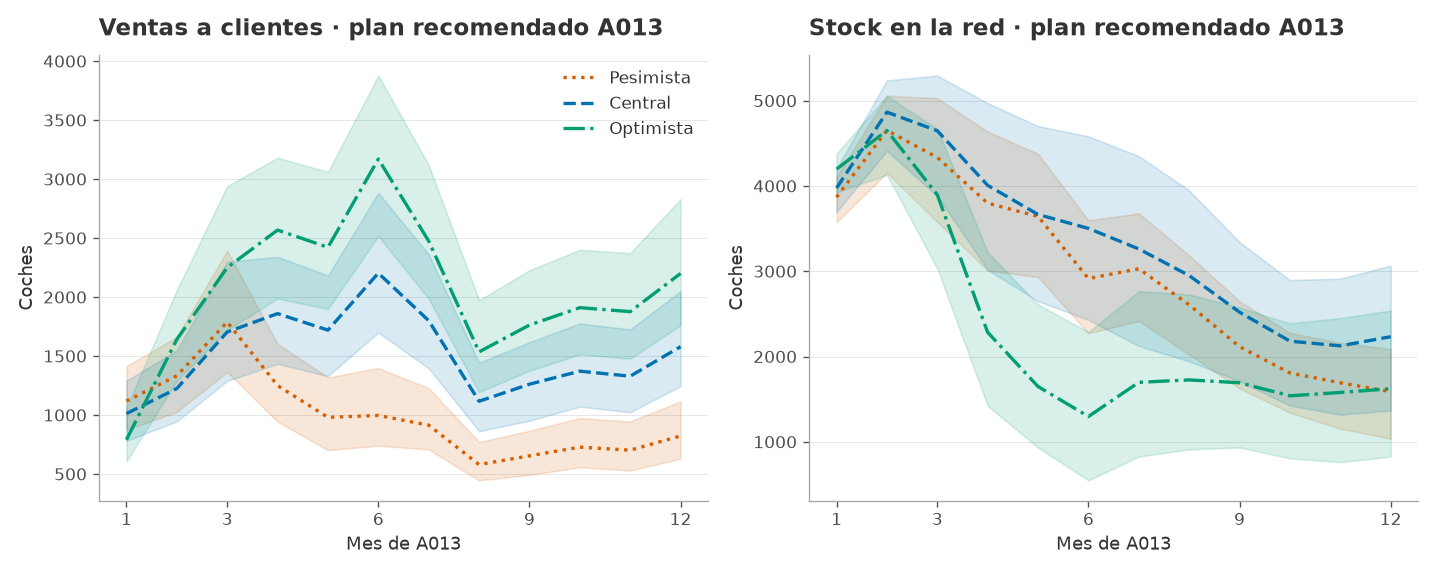

In [7]:
filas_mensual = []
for nombre, resultado in RES_REC.items():
    for metrica in ["ventas", "stock_fin", "llegadas", "resultado", "perdidas"]:
        v = resultado["mensual"][metrica]
        v = np.concatenate([v, v.sum(axis=2, keepdims=True)], axis=2)
        for m in range(HORIZONTE):
            for j, segmento in enumerate(SEGMENTOS + ["Total"]):
                valores = v[:, m, j]
                filas_mensual.append({"escenario": nombre, "segmento": segmento,
                                      "mes_horizonte": m + 1, "metrica": metrica,
                                      "media": valores.mean(), "mediana": np.median(valores),
                                      "p10": np.quantile(valores, .1), "p90": np.quantile(valores, .9)})
mensual_resumen = pd.DataFrame(filas_mensual)
guardar(mensual_resumen, "plan_recomendado_mensual_a013_a014")
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for eje, metrica, titulo in zip(ejes, ["ventas", "stock_fin"], ["Ventas a clientes", "Stock en la red"]):
    for nombre in ORDEN_ESC:
        q = mensual_resumen.query("segmento == 'Total' and metrica == @metrica and escenario == @nombre and mes_horizonte <= 12")
        eje.plot(q.mes_horizonte, q.mediana, label=nombre.capitalize(), color=COLORES[nombre], linestyle=TRAZOS[nombre])
        eje.fill_between(q.mes_horizonte, q.p10, q.p90, color=COLORES[nombre], alpha=.15)
    eje.set(title=f"{titulo} · plan recomendado A013", xlabel="Mes de A013", ylabel="Coches")
    eje.set_xticks([1, 3, 6, 9, 12])
ejes[0].legend()
fig.tight_layout()
figura(fig, "plan_recomendado_ventas_stock_a013")


Fuente: simulación del plan recomendado, 1.000 réplicas por escenario. Las líneas
son medianas y las bandas P10–P90. El total se calcula sumando los segmentos de
cada réplica antes de obtener los percentiles. Los coches en camino no están
incluidos en el stock en la red representado.


In [8]:
PLAN_REC = api_sim.crear_plan(DEM_PLAN, dd, SIGMA3, z=Z_REC)
filas_plan, filas_llegadas = [], []
for m in range(15):
    llegada_t = 145 + m
    decision_t = llegada_t - 3
    periodo_llegada = f"A{(llegada_t - 1)//12 + 1:03d}{(llegada_t - 1)%12 + 1:02d}01"
    periodo_decision = f"A{(decision_t - 1)//12 + 1:03d}{(decision_t - 1)%12 + 1:02d}01"
    for j, segmento in enumerate(SEGMENTOS):
        fila = {"segmento": segmento, "mes": (decision_t - 1) % 12 + 1,
                "periodo_decision": periodo_decision, "periodo_llegada": periodo_llegada,
                "pedido": int(PLAN_REC[m, j]),
                "estado": "comprometido estimado" if m < 2 else "plan inicial revisable"}
        filas_plan.append(fila)
        if m < 12:
            filas_llegadas.append({"segmento": segmento, "mes": m + 1,
                                   "periodo": periodo_llegada, "llegadas": int(PLAN_REC[m, j]),
                                   "periodo_decision": periodo_decision, "comprometida": m < 2})
plan_pedidos = pd.DataFrame(filas_plan)
guardar(plan_pedidos, "plan_pedidos_inicial_a013_a014")
guardar(pd.DataFrame(filas_llegadas), "plan_llegadas_inicial_a013")
display(Markdown("### Pedidos decididos durante A013 · plan inicial · coches"))
display(plan_pedidos[plan_pedidos.periodo_decision.str.startswith("A013")]
        .pivot(index="segmento", columns="mes", values="pedido").reindex(SEGMENTOS))
filas_pedidos_revisados = []
for nombre, resultado in RES_REC.items():
    for m in range(12):
        for j, segmento in enumerate(SEGMENTOS):
            v = resultado["pedidos"][:, m, j]
            filas_pedidos_revisados.append({"escenario": nombre, "segmento": segmento,
                                           "mes_decision_a013": m + 1,
                                           "mes_llegada_horizonte": m + 4,
                                           "media": v.mean(), "mediana": np.median(v),
                                           "p10": np.quantile(v, .1), "p90": np.quantile(v, .9)})
guardar(pd.DataFrame(filas_pedidos_revisados), "pedidos_revisados_a013")


### Pedidos decididos durante A013 · plan inicial · coches

mes,1,2,3,4,5,6,7,8,9,10,11,12
segmento,,,,,,,,,,,,
B,153,132,168,121,66,45,67,78,100,64,103,136
C,0,0,0,0,0,0,0,172,220,163,201,232
MD,0,15,59,36,17,29,42,33,33,31,40,45
SSUV,659,494,750,530,253,245,325,412,496,219,335,426
CSUV,0,218,347,310,149,112,191,253,272,122,185,257
MSUV,353,622,693,593,293,336,452,516,633,314,309,468
S,80,72,74,30,0,0,0,0,0,56,83,6


La tabla anterior es una propuesta inicial, no el promedio de los pedidos que
terminarán cursándose tras observar ventas. Enero–febrero de A013 se reciben de
compromisos anteriores; el pedido de diciembre de A012 llega en marzo. Los pedidos
decididos en octubre–diciembre de A013 llegan en enero–marzo de A014. La fabricación
se aproxima por la asignación ejecutada en el mes del pedido, sin un submodelo
adicional de capacidad o plazo de fábrica que el caso no proporciona.


In [9]:
prima = ficha.prima_co2_eur.to_numpy()
mensual_central = RES_REC["central"]["mensual"]
co2_misma_venta = (mensual_central["ventas"][:, :12] * prima).sum(axis=(1, 2))
resultado_sin = central["resultado"][:, -1]
resultado_con = resultado_sin - co2_misma_venta
co2_aislado = pd.DataFrame([
    {"comparacion": etiqueta, "media_eur": v.mean(), "mediana_eur": np.median(v),
     "p10_eur": np.quantile(v, .1), "p90_eur": np.quantile(v, .9)}
    for etiqueta, v in [("Central sin prima", resultado_sin),
                        ("Central con prima, mismos flujos", resultado_con),
                        ("Efecto aislado de prima", -co2_misma_venta)]
])
guardar(co2_aislado, "efecto_co2_aislado_a013")
unitaria = pd.DataFrame({"segmento": SEGMENTOS,
                         "beneficio_bruto_eur": ficha.beneficio_bruto_marca_eur.to_numpy(),
                         "vm_joven_eur": ficha.vm_real_0_90_eur.to_numpy(),
                         "cvp_joven_eur": (ficha.beneficio_bruto_marca_eur - ficha.vm_real_0_90_eur).to_numpy(),
                         "prima_co2_eur": prima,
                         "coste_max_stock_vida_eur": 360,
                         "coste_transfer_eur": .2 * ficha.beneficio_bruto_marca_eur.to_numpy()})
unitaria["cvp_joven_con_co2_eur"] = unitaria.cvp_joven_eur - prima
guardar(unitaria, "economia_unitaria_segmento")
coste_error = tabla5[tabla5.metrica.isin(["perdidas", "cvp_perdido_neto", "coste_stock", "coste_transfer", "vm"])].copy()
guardar(coste_error, "coste_de_equivocarse_a013")
display(co2_aislado.round())


,comparacion,media_eur,mediana_eur,p10_eur,p90_eur
0,Central sin prima,62882071.0,62780264.0,56448322.0,69472532.0
1,"Central con prima, mismos flujos",7874938.0,7817638.0,6070964.0,9831225.0
2,Efecto aislado de prima,-55007133.0,-54887214.0,-59891600.0,-50080741.0


La comparación anterior aísla CO₂ sobre exactamente las mismas ventas y flujos
centrales. No atribuye a la prima toda la diferencia entre escenarios, donde
también cambian demanda, producto, suministro y otros costes. Tampoco es la
respuesta óptima a una prima conocida: esa respuesta sí podría cambiar pedidos.
El almacenamiento de la marca está limitado a 360 €/coche a lo largo de su vida
facturada; no puede extrapolarse linealmente durante años. El VM por envejecimiento
y la financiación del concesionario son conceptos adicionales y distintos.


In [10]:
errores = BASE["errores"].copy()
filas_ventanas = []
for (origen, segmento), grupo in errores.groupby(["origen", "segmento"]):
    grupo = grupo.sort_values("t")
    observado = grupo.observado.rolling(3).sum()
    previsto = grupo.prevision.rolling(3).sum()
    for t, razon in zip(grupo.t, observado / previsto):
        if np.isfinite(razon):
            filas_ventanas.append({"origen": origen, "t": t, "segmento": segmento, "razon": razon})
ventanas = pd.DataFrame(filas_ventanas)
umbrales = []
for segmento in SEGMENTOS:
    valores = ventanas.loc[ventanas.segmento == segmento, "razon"]
    proxy = len(valores) < 6
    if proxy:
        valores = ventanas.loc[ventanas.segmento.isin(["SSUV", "MSUV"]), "razon"]
    minimo, maximo = valores.quantile([.1, .9])
    if proxy:
        minimo, maximo = max(0, 1 + 1.5 * (minimo - 1)), 1 + 1.5 * (maximo - 1)
    umbrales.append({"segmento": segmento, "razon_minima": minimo, "razon_maxima": maximo,
                     "ventanas": len(valores), "proxy": proxy,
                     "metodo": "cociente sumas 3 meses; proxy SSUV/MSUV ampliado ×1,5" if proxy else "cociente sumas 3 meses por origen"})
guardar(pd.DataFrame(umbrales), "umbrales_revision_a013")
guardar(ventanas, "ventanas_revision_historicas")
display(pd.DataFrame(umbrales).round(3))


,segmento,razon_minima,razon_maxima,ventanas,proxy,metodo
0,B,0.741,1.735,30,False,cociente sumas 3 meses por origen
1,C,0.880,1.196,30,False,cociente sumas 3 meses por origen
2,MD,0.666,0.919,30,False,cociente sumas 3 meses por origen
3,SSUV,0.941,2.051,30,False,cociente sumas 3 meses por origen
4,CSUV,0.763,2.246,60,True,cociente sumas 3 meses; proxy SSUV/MSUV amplia...
5,MSUV,0.803,1.296,30,False,cociente sumas 3 meses por origen
6,S,0.662,10.306,30,False,cociente sumas 3 meses por origen


Los umbrales se refieren al cociente de sumas que utiliza la regla operativa.
No se unen ventanas de años de validación diferentes. CSUV utiliza, si no hay
historia suficiente, una referencia SSUV/MSUV ampliada como sensibilidad explícita,
no un umbral validado. Ante stock agotado, una señal baja no justifica reducir la
demanda prevista automáticamente. Además se vigilan antigüedad, compromisos en
camino, costes confirmados y retrasos de producto o fábrica.


## 4. Sensibilidad de los supuestos y continuidad

Se usan las mismas 200 réplicas del piloto para contrastes acotados. Estas pruebas
cambian un supuesto cada vez; no son probabilidades ni intervalos de confianza.
El ahorro comercial de un transfer se compara con su disponibilidad real supuesta,
no con una capacidad europea ilimitada en el caso base.


In [11]:
pruebas = [
    ("Pipeline ×0,75", "central", {"multiplicador_pipeline": .75}, None, None),
    ("Pipeline ×1,25", "central", {"multiplicador_pipeline": 1.25}, None, None),
    ("Pipeline últimos 3 meses", "central", {"meses_pipeline": 3}, None, None),
    ("Edades iniciales −15 días", "central", {"edad_desplazamiento": -15}, None, None),
    ("Edades iniciales +15 días", "central", {"edad_desplazamiento": 15}, None, None),
    ("VM CSUV viejo ×1,25", "central", {"vm_csuv_mayor_factor": 1.25}, None, None),
    ("Transfer del 25 % del déficit", "central", {"transfer_fraccion": .25}, None, None),
    ("Transfer suficiente (cota favorable)", "central", {"transfer_fraccion": 1.0}, None, None),
    ("Errores independientes", "central", {}, None, generar_factores(N_REP, SD_LOG, 0, 0)[:N_PILOTO]),
    ("Persistencia y correlación 0,5", "central", {}, None, generar_factores(N_REP, SD_LOG, .5, .5)[:N_PILOTO]),
    ("Arancel adicional cero", "pesimista", {"arancel_eur": np.zeros(7)}, None, None),
    ("Arancel adicional 1.000 €/coche", "pesimista", {"arancel_eur": np.full(7, 1000.)}, None, None),
    ("Divisa sin ahorro", "optimista", {"cambio_eur": np.zeros(7)}, None, None),
    ("Divisa ahorro 500 €/coche", "optimista", {"cambio_eur": np.full(7, -500.)}, None, None),
    ("Pesimista sin frenar reposición negativa", "pesimista", {"frenar_no_rentables": False}, None, None),
]
alto_msuv = float(BASE["producto"].set_index("segmento").loc["MSUV", "efecto_alto"])
demora_producto = DEM_BRUTA["pesimista"].copy()
demora_producto[:3, SEGMENTOS.index("MSUV")] /= 1 + alto_msuv
pruebas.append(("Retraso MSUV: proxy de pérdida de cuota durante 3 meses", "pesimista", {},
                demanda_con_combustible("pesimista", COMBUSTIBLE["pesimista"], demora_producto)[0], None))
sin_producto = api_demanda.prever_escenario_revision(BASE, "optimista", {
    "producto": {s: 0.0 for s in ["B", "SSUV", "CSUV", "MSUV"]}, "sin_ledger": True}).to_numpy()
pruebas.append(("Optimista sin mejora adicional de producto", "optimista", {},
                demanda_con_combustible("optimista", COMBUSTIBLE["optimista"], sin_producto)[0], None))
for nombre in ["pesimista", "optimista"]:
    for cambio in [0., 2 * COMBUSTIBLE[nombre]]:
        pruebas.append((f"Combustible {nombre}: {cambio:+.0%}", nombre, {},
                        demanda_con_combustible(nombre, cambio)[0], None))
for multiplicador in [.75, 1.25]:
    d = DEM_ESC["central"].copy()
    d[:, SEGMENTOS.index("CSUV")] *= multiplicador
    pruebas.append((f"Demanda CSUV ×{multiplicador}", "central", {}, d, None))
for multiplicador in [2 / 3, 4 / 3]:
    sd_alternativa = SD_LOG.copy()
    sd_alternativa[SEGMENTOS.index("CSUV")] *= multiplicador
    factores_alternativos = generar_factores(N_REP, sd_alternativa, PHI, RHO)[:N_PILOTO]
    pruebas.append((f"Dispersión CSUV ×{multiplicador:.2f}", "central", {}, None,
                    factores_alternativos))
for multiplicador in [.9, 1.1]:
    d = DEM_ESC["central"].copy()
    d[12:] *= multiplicador
    pruebas.append((f"Continuidad A014 ×{multiplicador}", "central", {}, d, None))
ratios = errores.groupby("segmento").apply(lambda g: g.observado.sum() / g.prevision.sum(), include_groups=False)
sesgo_residual = ratios.reindex(SEGMENTOS).fillna(1).to_numpy()
pruebas.append(("Sesgo residual histórico sin centrar", "central", {}, DEM_ESC["central"] * sesgo_residual, None))
filas_sens = []
for etiqueta, nombre, parametros_extra, d, factores in pruebas:
    salida = ejecutar(nombre, Z_REC, FACTORES_PILOTO if factores is None else factores,
                      parametros_extra, d)
    m13, m18 = metricas_anuales(salida), metricas_anuales(salida, 0, 18)
    filas_sens.append({"sensibilidad": etiqueta, "escenario": nombre,
                       "resultado_a013_media_eur": m13["resultado"][:, -1].mean(),
                       "resultado_18_meses_media_eur": m18["resultado"][:, -1].mean(),
                       "servicio_a013": m13["servicio"][:, -1].mean(),
                       "stock_diciembre": m13["stock_fin"][:, -1].mean()})
sensibilidades = pd.DataFrame(filas_sens)
guardar(sensibilidades, "sensibilidades_plan_recomendado")
continuidad = []
for politica_nombre, resultados in [("base", RES_BASE), ("recomendado", RES_REC)]:
    for nombre, salida in resultados.items():
        anual, extendido = metricas_anuales(salida), metricas_anuales(salida, 0, 18)
        continuidad.append({"politica": politica_nombre, "escenario": nombre,
                            "resultado_a013_eur": anual["resultado"][:, -1].mean(),
                            "resultado_18_meses_eur": extendido["resultado"][:, -1].mean(),
                            "stock_junio_a014": extendido["stock_fin"][:, -1].mean()})
guardar(pd.DataFrame(continuidad), "comparacion_continuidad_politicas")
display(sensibilidades.round(2))


,sensibilidad,escenario,resultado_a013_media_eur,resultado_18_meses_media_eur,servicio_a013,stock_diciembre
0,"Pipeline ×0,75",central,63320669.90,9.326506e+07,0.97,2182.86
1,"Pipeline ×1,25",central,63322505.84,9.321596e+07,0.98,2223.54
2,Pipeline últimos 3 meses,central,62677150.56,9.260470e+07,0.97,2195.03
3,Edades iniciales −15 días,central,63485343.37,9.342258e+07,0.98,2191.20
4,Edades iniciales +15 días,central,63305099.48,9.324234e+07,0.98,2191.20
5,"VM CSUV viejo ×1,25",central,63286165.66,9.318191e+07,0.98,2191.20
6,Transfer del 25 % del déficit,central,63632806.65,9.366151e+07,0.98,2208.58
7,Transfer suficiente (cota favorable),central,64291696.71,9.459084e+07,1.00,2286.26
8,Errores independientes,central,63599031.26,9.376955e+07,0.98,2177.01
9,"Persistencia y correlación 0,5",central,63255447.12,9.298255e+07,0.97,2182.32


La prolongación muestra consecuencias de los pedidos finales y permite comparar
la estabilidad de la elección, sin añadir una venta ficticia del inventario.
No demuestra un óptimo económico infinito. Los costes incrementales de importación
pendientes en el stock final se informan separados de los imputados al vehículo
vendido. Las sensibilidades de CSUV, edades, costes y sesgo residual permiten
distinguir incertidumbre del modelo de variación aleatoria mensual.


In [12]:
comprobaciones = []
for nombre, salida in RES_REC.items():
    m = salida["mensual"]
    balance = m["stock_inicial"] + m["llegadas"] - m["ventas_red"] - m["stock_fin"]
    demanda_balance = m["demanda"] - m["ventas"] - m["perdidas"]
    assert np.max(np.abs(balance)) < 1e-8
    assert np.max(np.abs(demanda_balance)) < 1e-8
    assert np.min(m["stock_fin"]) >= 0
    assert np.allclose(salida["plan_inicial"], PLAN_REC)
    for k in ["ventas", "perdidas", "stock_fin", "llegadas", "transfers"]:
        assert np.allclose(m[k], np.rint(m[k]))
    comprobaciones.append({"escenario": nombre, "balance_maximo": np.abs(balance).max(),
                            "demanda_balance_maximo": np.abs(demanda_balance).max(),
                            "mismo_plan_inicial": True, "unidades_enteras": True})
assert np.array_equal(FACTORES, generar_factores(N_REP, SD_LOG, PHI, RHO))
assert len(tabla5.segmento.unique()) == 8 and len(tabla5.escenario.unique()) == 3
assert plan_pedidos.query("periodo_decision == 'A0131201'").periodo_llegada.eq("A0140301").all()
guardar(pd.DataFrame(comprobaciones), "comprobaciones_revision")
filas_precision = []
for nombre, salida in RES_REC.items():
    valores = metricas_anuales(salida)["resultado"][:, -1]
    filas_precision.append({"escenario": nombre, "media_500": valores[:500].mean(),
                            "media_1000": valores.mean(), "ee_media_1000": valores.std(ddof=1) / np.sqrt(N_REP),
                            "prob_resultado_negativo_condicional": (valores < 0).mean()})
guardar(pd.DataFrame(filas_precision), "precision_monte_carlo_a013")
import statsmodels
import importlib.metadata
versiones = {"python": platform.python_version(), "numpy": np.__version__,
             "pandas": pd.__version__, "statsmodels": statsmodels.__version__,
             "semilla": SEMILLA, "replicas": N_REP, "piloto": N_PILOTO,
             "modelo": str(BASE["modelo_elegido"]), "horizonte_meses": HORIZONTE,
             "objetivo_servicio": OBJETIVO_SERVICIO,
             "estado": "ejecución final revisada"}
versiones["bibliotecas"] = {nombre: importlib.metadata.version(nombre)
                           for nombre in ["numpy", "pandas", "statsmodels", "scipy", "matplotlib",
                                          "python-docx", "python-pptx", "nbclient"]}
(TABLAS / "configuracion_ejecucion.json").write_text(json.dumps(versiones, ensure_ascii=False, indent=2) + "\n")


503

In [13]:
fila_central = tabla5.query("escenario == 'central' and segmento == 'Total'").set_index("metrica")
factible = bool(politica.objetivo_verificado.all())
limitaciones = [
    "A012 es evaluación retrospectiva; ya influyó en el desarrollo inicial.",
    "CSUV tiene poca historia: cuota, lanzamiento e incertidumbre requieren sensibilidad.",
    "Pipeline, fechas de producto, combustible, arancel y divisa incluyen supuestos explícitos.",
    "No hay automatriculaciones ni transfers garantizados en la política base.",
    "A014 es continuidad supuesta; el resultado es contribución tras costes modelizados.",
    "Producto central neutro por identificación insuficiente; el retraso se contrasta como sensibilidad.",
]
for nombre, grupo in ledger_escenarios.groupby("escenario"):
    if grupo.no_aplicado.sum() > .01:
        limitaciones.append(f"{nombre.capitalize()}: {numero(grupo.no_aplicado.sum())} coches de adelanto no caben en la caída supuesta; no se trasladan a otro mes.")
if not factible:
    pendientes_servicio = ", ".join(politica.loc[~politica.objetivo_verificado, "segmento"])
    limitaciones.append(f"El servicio medio objetivo no se alcanza en {pendientes_servicio}; no se oculta con el total.")
display(Markdown(
    f"## Recomendación\n\nLa política evaluada estima **{numero(fila_central.loc['ventas', 'media'])} ventas** "
    f"y **{numero(fila_central.loc['resultado', 'media'] / 1e6, 2)} M€** de contribución media central tras costes. "
    f"El servicio total medio es **{numero(100 * fila_central.loc['servicio', 'media'], 1)} %**. "
    + ("El objetivo se verifica en los segmentos viables." if factible else "El objetivo por segmento presenta las excepciones indicadas en la tabla de política.")
    + "\n\nEs la mejor opción entre las políticas comparadas bajo los supuestos declarados; no un óptimo global. "
    "Mantener los compromisos, revisar a tres meses y separar las decisiones de abastecimiento de un presupuesto comercial no estimado.\n\n"
    + "\n".join(f"- {x}" for x in limitaciones)))


## Recomendación

La política evaluada estima **18.539 ventas** y **62,88 M€** de contribución media central tras costes. El servicio total medio es **97,6 %**. El objetivo se verifica en los segmentos viables.

Es la mejor opción entre las políticas comparadas bajo los supuestos declarados; no un óptimo global. Mantener los compromisos, revisar a tres meses y separar las decisiones de abastecimiento de un presupuesto comercial no estimado.

- A012 es evaluación retrospectiva; ya influyó en el desarrollo inicial.
- CSUV tiene poca historia: cuota, lanzamiento e incertidumbre requieren sensibilidad.
- Pipeline, fechas de producto, combustible, arancel y divisa incluyen supuestos explícitos.
- No hay automatriculaciones ni transfers garantizados en la política base.
- A014 es continuidad supuesta; el resultado es contribución tras costes modelizados.
- Producto central neutro por identificación insuficiente; el retraso se contrasta como sensibilidad.
- Optimista: 235 coches de adelanto no caben en la caída supuesta; no se trasladan a otro mes.

## 5. Regeneración de la entrega

El resumen y la presentación se construyen con las tablas de esta misma ejecución.
Las cifras del plan inicial no se sustituyen por medias de revisiones posteriores.
El detalle de los ocho ámbitos (siete segmentos y total) está en la tabla 5 anterior
y en su CSV. La conversión a PDF utiliza LibreOffice cuando está instalado.


In [14]:
serie_entrega = BASE["serie"]
observado_anual = serie_entrega.groupby("anio").demanda_observada.sum()
comparable_anual = serie_entrega[serie_entrega.segmento != "CSUV"].groupby("anio").demanda_observada.sum()
ajustado_anual = serie_entrega.groupby("anio").demanda_subyacente.sum()
metricas_entrega = BASE["metricas"]
metricas_a012 = metricas_entrega[metricas_entrega.origen.eq(132) & metricas_entrega.fase.eq("retrospectiva_A012")]
total_comparable = metricas_a012[metricas_a012.segmento.astype(str).str.startswith("Total")]
if "modelo" in total_comparable and len(total_comparable) > 1:
    total_comparable = total_comparable[total_comparable.modelo.eq(BASE["modelo_elegido"])]
assert len(total_comparable) == 1, "La entrega necesita una métrica A012 del total comparable seleccionado"
pedidos_iniciales_a013 = plan_pedidos[plan_pedidos.periodo_decision.str.startswith("A013")].pedido.sum()
hallazgos = [
    f"Plan inicial: {numero(pedidos_iniciales_a013)} coches asignados a pedidos decididos en A013; "
    f"{numero(PLAN_REC[:12].sum())} llegadas previstas en A013. Son flujos distintos.",
    f"La prima de CO₂ reduce la contribución central en {numero(co2_misma_venta.mean()/1e6, 2)} M€ "
    "si se mantienen exactamente las mismas ventas y flujos.",
]
from datetime import date
contexto_entrega = {
    "modelo": str(BASE["modelo_elegido"]),
    "crecimiento_observado": float(observado_anual["A012"] / observado_anual["A011"] - 1),
    "crecimiento_comparable": float(comparable_anual["A012"] / comparable_anual["A011"] - 1),
    "crecimiento_ajustado": float(ajustado_anual["A012"] / ajustado_anual["A011"] - 1),
    "mae_relativo_a012": float(total_comparable.iloc[0].mae_pct),
    "co2_aislado_meur": float(-co2_misma_venta.mean() / 1e6),
    "fecha": date.today().isoformat(), "limitaciones": limitaciones,
    "hallazgos": hallazgos, "servicio_factible": factible,
    "ruta_figura_stock": str(FIGURAS / "plan_recomendado_ventas_stock_a013.png"),
}
(TABLAS / "contexto_entrega.json").write_text(json.dumps(contexto_entrega, ensure_ascii=False, indent=2) + "\n")
# Las definiciones y la llamada del generador se incorporan en las celdas siguientes.


1356

In [15]:
from pathlib import Path
import math
import shutil
import subprocess
import tempfile

from docx import Document
from docx.shared import Cm, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT, WD_CELL_VERTICAL_ALIGNMENT
from docx.oxml.ns import qn
from pptx import Presentation
from pptx.chart.data import CategoryChartData
from pptx.enum.chart import XL_CHART_TYPE, XL_LEGEND_POSITION
from pptx.enum.text import PP_ALIGN, MSO_ANCHOR
from pptx.util import Inches, Pt as PPTPt
from pptx.dml.color import RGBColor as PPTColor
from pptx.enum.shapes import MSO_SHAPE


def generar_entrega_revision(contexto, tabla5, plan, politica, carpeta=Path("../docs")):
    """Genera resumen, presentación y PDF con los results de revisión recibidos."""
    import pandas as pd

    requeridas_contexto = {
        "modelo", "crecimiento_observado", "crecimiento_comparable",
        "crecimiento_ajustado", "mae_relativo_a012", "co2_aislado_meur",
        "fecha", "limitaciones", "hallazgos", "servicio_factible",
    }
    faltan = requeridas_contexto - set(contexto)
    if faltan:
        raise ValueError(f"Faltan claves en contexto: {sorted(faltan)}")
    if not isinstance(contexto["limitaciones"], (list, tuple)) or not isinstance(contexto["hallazgos"], (list, tuple)):
        raise TypeError("limitaciones y hallazgos deben ser listas o tuplas")
    columnas_t5 = {"escenario", "segmento", "metrica", "media", "mediana", "p10", "p90"}
    columnas_plan = {"segmento", "mes", "periodo_decision", "periodo_llegada", "pedido", "estado"}
    columnas_pol = {"segmento", "z", "servicio_central", "viable"}
    for nombre, df, cols in (("tabla5", tabla5, columnas_t5), ("plan", plan, columnas_plan), ("politica", politica, columnas_pol)):
        if not isinstance(df, pd.DataFrame) or not cols.issubset(df.columns):
            raise ValueError(f"{nombre} debe ser DataFrame con columnas {sorted(cols)}")
    orden_esc = ["pesimista", "central", "optimista"]
    if set(tabla5["escenario"].dropna()) != set(orden_esc):
        raise ValueError("tabla5 debe contener exactamente los escenarios pesimista, central y optimista")
    metricas = {"ventas", "demanda", "pedidos_a013", "llegadas", "stock_medio", "cobertura_media", "stock_mas_90_fin", "coste_stock", "perdidas", "transfers", "coste_transfer", "vm", "cvp", "coste_co2", "coste_arancel", "coste_cambio", "resultado", "servicio", "cvp_perdido_neto", "stock_fin"}
    if not metricas.issubset(set(tabla5["metrica"].dropna())):
        raise ValueError("tabla5 no contiene todas las métricas definidas")
    carpeta = Path(carpeta)
    carpeta.mkdir(parents=True, exist_ok=True)
    docx_path, pptx_path = carpeta / "resumen-ejecutivo.docx", carpeta / "presentacion.pptx"
    orden_segmento = ["B", "C", "MD", "SSUV", "CSUV", "MSUV", "S"]
    def fmt(x, dec=0):
        if pd.isna(x):
            return "—"
        s = f"{float(x):,.{dec}f}"
        return s.replace(",", "X").replace(".", ",").replace("X", ".")
    def val(esc, seg, met, campo="mediana"):
        x = tabla5.loc[(tabla5.escenario == esc) & (tabla5.segmento == seg) & (tabla5.metrica == met), campo]
        return float(x.iloc[0]) if len(x) else float("nan")
    def fila(esc, met, campo="mediana"):
        return tabla5.loc[(tabla5.escenario == esc) & (tabla5.segmento == "Total") & (tabla5.metrica == met), campo]
    segmentos = [s for s in orden_segmento if s in set(tabla5.segmento)]
    central_ventas = tabla5[(tabla5.escenario == "central") & (tabla5.metrica == "ventas") & (tabla5.segmento != "Total")]
    principales = central_ventas.sort_values("mediana", ascending=False).segmento.tolist()[:3]
    if not principales:
        principales = segmentos[:3]
    def total(m, e="central", c="mediana"):
        x = fila(e, m, c)
        return float(x.iloc[0]) if len(x) else float("nan")
    def pct(x): return "—" if pd.isna(x) else fmt(100*x, 1) + " %"
    candidatos = politica[politica.viable.fillna(False).astype(bool)]
    if candidatos.empty:
        candidatos = politica
    politica_incumplida = candidatos[pd.to_numeric(candidatos.servicio_central, errors="coerce") < 0.95]
    nombres_incumplidos = [str(x) for x in politica_incumplida.segmento.tolist()]
    if nombres_incumplidos:
        recomendacion = ("La política evaluada presenta déficit frente al objetivo de servicio del 95 % en " + ", ".join(nombres_incumplidos) + ". Los compromisos iniciales y los escenarios limitan el cumplimiento.")
    else:
        recomendacion = "La mejor política evaluada alcanza al menos un 95 % de servicio medio por segmento en el escenario central; mantener revisión mensual y seguimiento de compromisos."

    # Documento ejecutivo: dos páginas explícitas, A4, márgenes y tipografía de la guía.
    doc = Document()
    zoom = doc.settings.element.find(qn("w:zoom"))
    if zoom is not None:
        zoom.set(qn("w:percent"), "100")
    sec = doc.sections[0]
    sec.page_width, sec.page_height = Cm(21), Cm(29.7)
    sec.top_margin = sec.bottom_margin = sec.left_margin = sec.right_margin = Cm(2)
    normal = doc.styles["Normal"]
    normal.font.name = "Arial"; normal.font.size = Pt(11); normal.font.color.rgb = RGBColor(45, 55, 65)
    normal.paragraph_format.line_spacing = 1.15
    for style_name, size in (("Title", 16), ("Heading 1", 16), ("Heading 2", 12)):
        st = doc.styles[style_name]; st.font.name = "Arial"; st.font.size = Pt(size); st.font.bold = True; st.font.color.rgb = RGBColor(0, 75, 125)
    def titulo(texto, nivel=1): doc.add_heading(texto, level=nivel)
    def par(texto, negrita=False):
        p = doc.add_paragraph(); r = p.add_run(str(texto)); r.bold = negrita; return p
    def tabla(headers, rows, font=8.5):
        t = doc.add_table(rows=1, cols=len(headers)); t.alignment = WD_TABLE_ALIGNMENT.CENTER; t.style = "Table Grid"
        for i, h in enumerate(headers): t.rows[0].cells[i].text = str(h)
        for row in rows:
            cells = t.add_row().cells
            for i, x in enumerate(row): cells[i].text = str(x)
        for ri, row in enumerate(t.rows):
            for cell in row.cells:
                cell.vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
                for p in cell.paragraphs:
                    p.paragraph_format.space_after = Pt(1); p.paragraph_format.space_before = Pt(1)
                    for r in p.runs:
                        r.font.name = "Arial"; r.font.size = Pt(font)
                        if ri == 0: r.bold = True; r.font.color.rgb = RGBColor(0, 75, 125)
        return t
    p = doc.add_paragraph(); p.alignment = WD_ALIGN_PARAGRAPH.CENTER
    r = p.add_run("RESUMEN EJECUTIVO · " + str(contexto["fecha"])); r.bold = True; r.font.name = "Arial"; r.font.size = Pt(16); r.font.color.rgb = RGBColor(0, 75, 125)
    par(recomendacion, True)
    nombre_modelo = {"conf_intercepto": "mercado con confianza y constante",
                     "conf_sin_intercepto": "mercado con confianza sin constante",
                     "macro": "mercado con confianza, paro y crédito",
                     "estacional": "referencia estacional"}.get(str(contexto["modelo"]), str(contexto["modelo"]))
    par("Modelo: " + nombre_modelo + ". Ventas: mediana; contribución y servicio: medias. P10–P90 describe variación dentro de cada escenario, no su probabilidad.")
    titulo("Escenarios A013", 2)
    tabla(["Escenario", "Ventas (coches)", "Resultado medio (M€)", "P10–P90 (M€)", "Servicio medio"], [[e.capitalize(), fmt(total("ventas",e)), fmt(total("resultado",e,"media")/1e6,1), f"{fmt(total('resultado',e,'p10')/1e6,1)}–{fmt(total('resultado',e,'p90')/1e6,1)}", pct(total("servicio",e,"media"))] for e in orden_esc], 8.5)
    titulo("Stock y economía del plan revisado · medias A013", 2)
    indicadores = [
        ("Pedidos decididos A013 (coches)", "pedidos_a013", 1, 0),
        ("Stock medio (coches)", "stock_medio", 1, 0),
        ("Cobertura media (meses)", "cobertura_media", 1, 1),
        ("Más de 90 días al cierre (coches)", "stock_mas_90_fin", 1, 0),
        ("Coste de stock (M€)", "coste_stock", 1e6, 2),
        ("Ventas perdidas (coches)", "perdidas", 1, 0),
        ("VM (M€)", "vm", 1e6, 2),
        ("CVP antes de logística y primas (M€)", "cvp", 1e6, 2),
        ("Prima CO₂ (M€)", "coste_co2", 1e6, 2),
        ("Arancel adicional (M€)", "coste_arancel", 1e6, 2),
        ("Cambio: coste / ahorro (M€)", "coste_cambio", 1e6, 2),
    ]
    tabla(["Indicador", "Pesimista", "Central", "Optimista"],
          [[etiqueta] + [fmt(total(metrica, e, "media") / divisor, dec) for e in orden_esc]
           for etiqueta, metrica, divisor, dec in indicadores], 8.5)
    titulo("Indicadores por segmento · escenario central", 2)
    tabla(["Segmento", "Ventas (coches)", "Demanda (coches)", "Cobertura (meses)", "Servicio medio"], [[s, fmt(val("central",s,"ventas")), fmt(val("central",s,"demanda")), fmt(val("central",s,"cobertura_media"),1), pct(val("central",s,"servicio","media"))] for s in segmentos], 8.5)
    for h in list(contexto["hallazgos"])[:2]: par(str(h))
    doc.add_page_break()
    titulo("Plan de fabricación A013", 1)
    par("Plan inicial: pedidos de fabricación asignados a A013 por mes de decisión; no son las llegadas ni los pedidos revisados de tabla 5.")
    p13 = plan[plan.periodo_decision.astype(str).str.startswith("A013", na=False)].copy()
    # La tabla conserva el calendario de decisión A013 aunque no haya pedido en un mes.
    meses = list(range(1, 13))
    p13["_mes"] = pd.to_numeric(p13.mes, errors="coerce")
    faltan_mes = p13["_mes"].isna()
    p13.loc[faltan_mes, "_mes"] = pd.to_numeric(
        p13.loc[faltan_mes, "periodo_decision"].astype(str).str.extract(r"(\d{1,2})$")[0],
        errors="coerce",
    )
    agreg = p13.groupby(["segmento", "_mes"], dropna=False).pedido.sum()
    filas = [[s] + [fmt(agreg.get((s,m),0)) for m in meses] for s in segmentos]
    filas.append(["Total"] + [fmt(sum(agreg.get((s,m),0) for s in segmentos)) for m in meses])
    tabla(["Seg."] + [str(m) for m in meses], filas, 8.5)
    # Llegada por plazo ilustrativo con fuente explícita de periodos del plan.
    par("La llegada ocurre en t+3: cada celda indica el mes del pedido, no el de llegada. Los pedidos de cierre A013 llegan en la prolongación de A014, fuera del horizonte anual A013.")
    titulo("Riesgos, límites y acción", 2)
    for item in list(contexto["limitaciones"])[:3]: doc.add_paragraph(str(item), style="List Bullet")
    if any("no caben" in str(x) for x in contexto["limitaciones"]):
        for item in contexto["limitaciones"]:
            if "no caben" in str(item): doc.add_paragraph(str(item), style="List Bullet")
    par("Caso base: cero automatriculaciones y cero transfers, también cero coste de transfer. "
        "El servicio se exige en media central; no se garantiza en cada réplica ni en los extremos. "
        "La continuidad hasta junio A014 es una sensibilidad, sin valoración ficticia del stock.")
    par("Crecimiento observado: " + pct(contexto["crecimiento_observado"]) + "; gama comparable: " + pct(contexto["crecimiento_comparable"]) + "; ajuste parcial de episodios: " + (pct(contexto["crecimiento_ajustado"]) if contexto["crecimiento_ajustado"] is not None else "no disponible") + ". MAE mensual relativo A012, total sin CSUV: " + pct(contexto["mae_relativo_a012"]) + ". CO₂ aislado: " + fmt(contexto["co2_aislado_meur"],2) + " M€ sobre los mismos flujos centrales.")
    par("La tabla 5 completa se conserva en el CSV de results del notebook.")
    doc.save(docx_path)

    # Presentación 16:9 con gráficos de PowerPoint editables y notas de exposición.
    prs = Presentation(); prs.slide_width = Inches(13.333); prs.slide_height = Inches(7.5)
    prs.core_properties.title = "Revisión de escenarios A013"
    azul, gris, verde, naranja = "0072B2", "333333", "009E73", "D55E00"
    def rgb(h): return PPTColor.from_string(h)
    def nueva(titulo, nota):
        sl = prs.slides.add_slide(prs.slide_layouts[6]); sl.background.fill.solid(); sl.background.fill.fore_color.rgb = rgb("FFFFFF")
        box = sl.shapes.add_textbox(Inches(.55), Inches(.35), Inches(12.2), Inches(.65)); tf=box.text_frame; tf.clear(); p=tf.paragraphs[0]; p.text=titulo; p.font.name="Arial"; p.font.size=PPTPt(30); p.font.bold=True; p.font.color.rgb=rgb(azul)
        sl.notes_slide.notes_text_frame.text = "\n".join([nota, "Tiempo orientativo: 1 min 15 s."])
        return sl
    def texto(sl, lines, x=.7, y=1.35, w=5.5, h=4.8, size=21):
        sh=sl.shapes.add_textbox(Inches(x), Inches(y), Inches(w), Inches(h)); tf=sh.text_frame; tf.clear(); tf.word_wrap=True
        for i,line in enumerate(lines):
            p=tf.paragraphs[0] if i==0 else tf.add_paragraph(); p.text=str(line); p.font.name="Arial"; p.font.size=PPTPt(size); p.font.color.rgb=rgb(gris); p.space_after=PPTPt(14)
        return sh
    def tarjetas(sl, items, x=.8, y=2.0, w=3.7, h=1.35, gap=.35):
        for i, (label, value) in enumerate(items):
            xx=x+i*(w+gap)
            shape=sl.shapes.add_shape(MSO_SHAPE.ROUNDED_RECTANGLE, Inches(xx), Inches(y), Inches(w), Inches(h))
            shape.fill.solid(); shape.fill.fore_color.rgb=rgb("EAF3F8"); shape.line.color.rgb=rgb("D3E2EC")
            tf=shape.text_frame; tf.clear(); tf.vertical_anchor=MSO_ANCHOR.MIDDLE
            p=tf.paragraphs[0]; p.text=str(value); p.alignment=PP_ALIGN.CENTER; p.font.name="Arial"; p.font.size=PPTPt(25); p.font.bold=True; p.font.color.rgb=rgb(azul)
            p=tf.add_paragraph(); p.text=str(label); p.alignment=PP_ALIGN.CENTER; p.font.name="Arial"; p.font.size=PPTPt(15); p.font.color.rgb=rgb(gris)
    def proceso(sl, pasos, y=3.0):
        n=len(pasos); ancho=11.8/n
        for i, paso in enumerate(pasos):
            xx=.75+i*ancho
            sh=sl.shapes.add_shape(MSO_SHAPE.ROUNDED_RECTANGLE, Inches(xx), Inches(y), Inches(ancho-.3), Inches(.95))
            sh.fill.solid(); sh.fill.fore_color.rgb=rgb("EAF3F8"); sh.line.color.rgb=rgb(azul)
            tf=sh.text_frame; tf.text=paso; tf.vertical_anchor=MSO_ANCHOR.MIDDLE
            for p in tf.paragraphs: p.alignment=PP_ALIGN.CENTER; p.font.name="Arial"; p.font.size=PPTPt(18); p.font.color.rgb=rgb(gris)
            if i<n-1:
                ar=sl.shapes.add_shape(MSO_SHAPE.RIGHT_ARROW, Inches(xx+ancho-.33), Inches(y+.28), Inches(.35), Inches(.36)); ar.fill.solid(); ar.fill.fore_color.rgb=rgb(azul); ar.line.fill.background()
    def chart(sl, categories, series, x=6.5,y=1.5,w=6.1,h=4.7, typ=XL_CHART_TYPE.COLUMN_CLUSTERED):
        data=CategoryChartData(); data.categories=[str(c) for c in categories]
        for name, vals in series: data.add_series(name, [0 if pd.isna(v) else float(v) for v in vals])
        ch=sl.shapes.add_chart(typ, Inches(x), Inches(y), Inches(w), Inches(h), data).chart
        ch.has_legend=True; ch.legend.position=XL_LEGEND_POSITION.BOTTOM; ch.legend.include_in_layout=False
        ch.has_title=False
        palette=[azul, "888888", verde]
        for si, ser in enumerate(ch.series):
            color=palette[si % len(palette)]
            ser.format.fill.solid(); ser.format.fill.fore_color.rgb=rgb(color); ser.format.line.color.rgb=rgb(color)
            if len(ch.series)==1 and [str(c).lower() for c in categories] == ["pesimista", "central", "optimista"]:
                for point, point_color in zip(ser.points, [naranja, azul, verde]):
                    point.format.fill.solid(); point.format.fill.fore_color.rgb=rgb(point_color)
        ch.value_axis.has_major_gridlines=True
        numeros = [float(v) for _, valores in series for v in valores if not pd.isna(v)]
        ch.value_axis.minimum_scale = min(0., min(numeros) * 1.05) if numeros else 0.
        if any("(%)" in str(nombre) for nombre, _ in series):
            ch.value_axis.maximum_scale = 100.
        ch.category_axis.tick_labels.font.name = "Arial"
        ch.category_axis.tick_labels.font.size = PPTPt(15)
        ch.value_axis.tick_labels.font.name = "Arial"
        ch.value_axis.tick_labels.font.size = PPTPt(15)
        ch.legend.font.name = "Arial"
        ch.legend.font.size = PPTPt(14)
        return ch
    # 1 recomendación
    sl=nueva("A013: margen con servicio y revisión mensual", "Abrir con la recomendación condicionada al indicador de factibilidad. No se asignan probabilidades a los escenarios. Explicar que se trata de results simulados.")
    texto(sl,[recomendacion],.8,1.35,11.7,1.4,21)
    tarjetas(sl,[("Resultado medio central (M€)",fmt(total("resultado",c="media")/1e6,1)),("Servicio medio central",pct(total("servicio",c="media"))), ("MAE A012 sin CSUV",pct(contexto["mae_relativo_a012"]))],1.0,3.25,3.55,1.45,.55)
    # 2 demanda observada/subyacente
    sl=nueva("A012: crece el total, no la gama comparable", "Diferenciar ventas observadas, gama comparable y ajuste parcial de episodios. La estimación ajustada no identifica toda la demanda potencial ni la demanda perdida por falta de stock.")
    items=[("Observado",pct(contexto["crecimiento_observado"])),("Comparable",pct(contexto["crecimiento_comparable"]))]
    if contexto["crecimiento_ajustado"] is not None: items.append(("Ajuste parcial de episodios",pct(contexto["crecimiento_ajustado"])))
    tarjetas(sl,items,1.1,2.2,3.3,1.45,.6)
    texto(sl,["Crecimiento observado y comparable son referencias distintas; no equivalen por sí solos a la demanda futura."],1.0,4.35,10.5,1.1,20)
    # 3 validación
    sl=nueva("A012: evaluación retrospectiva, sin CSUV", "Modelo seleccionado con A009–A011. A012 ya fue observado en el desarrollo inicial y no se presenta como prueba independiente. El MAE mensual relativo divide el error absoluto medio por las ventas mensuales medias del total comparable.")
    tarjetas(sl,[("MAE mensual relativo, sin CSUV",pct(contexto["mae_relativo_a012"]))],1.0,1.8,4.8,1.45,.4)
    texto(sl,["Selección con A009–A011; evaluación retrospectiva A012.", "CSUV utiliza una sensibilidad específica, no la precisión del total comparable."],.9,4.0,10.9,1.6,21)
    # 4 forecast/plan
    sl=nueva("Pedir hoy para recibir dentro de tres meses", "Mostrar pedidos del plan inicial agrupados por mes de decisión. La serie de fabricación/pedido no es la serie de llegadas. Pedidos de cierre llegan en la prolongación de A014.")
    plan13=plan[plan.periodo_decision.astype(str).str.startswith("A013",na=False)].copy()
    plan13["_mes"]=pd.to_numeric(plan13.mes,errors="coerce")
    faltan_mes=plan13["_mes"].isna()
    plan13.loc[faltan_mes,"_mes"]=pd.to_numeric(plan13.loc[faltan_mes,"periodo_decision"].astype(str).str.extract(r"(\d{1,2})$")[0],errors="coerce")
    ped_mes=plan13.groupby("_mes").pedido.sum().reindex(range(1,13),fill_value=0)
    chart(sl,list(range(1,13)),[("Pedido inicial A013",ped_mes.tolist())],.85,1.35,11.5,3.25)
    proceso(sl,["Decisión / pedido", "Llegada t+3"],y=5.0)
    texto(sl,["Pedidos de cierre: llegada en prolongación A014."],8.25,6.0,4.2,.6,16)
    # 5 escenarios native chart
    sl=nueva("Tres escenarios, un mismo plan inicial", "Comparar mediana de ventas y contribución media total en el mismo orden de la tabla 5. P10–P90 describe variabilidad interna, no probabilidades de los escenarios. Arancel, divisa y combustible contienen tamaños exploratorios explícitos.")
    chart(sl, [e.capitalize() for e in orden_esc], [("Ventas (coches)",[total("ventas",e) for e in orden_esc])], 1.0,1.5,5.2,4.7)
    chart(sl, [e.capitalize() for e in orden_esc], [("Resultado medio (M€)",[total("resultado",e,"media")/1e6 for e in orden_esc])], 6.9,1.5,5.2,4.7)
    # 6 economía y CO2
    sl=nueva("CO₂: aislar el coste manteniendo los flujos", "La diferencia se calcula cargando la prima a las mismas ventas centrales. No se atribuye a CO₂ toda la distancia central–pesimista ni se reoptimiza en este contraste.")
    tarjetas(sl,[("Efecto CO₂ aislado (M€)",fmt(contexto["co2_aislado_meur"],2)),("Resultado medio central (M€)",fmt(total("resultado",c="media")/1e6,1))],1.0,2.0,4.5,1.5,.7)
    texto(sl,["VM, CVP y costes logísticos deben leerse por separado."],1.0,4.35,10.2,1.0,21)
    # 7 reglas
    sl=nueva("Servicio por segmento y señales de revisión", "El servicio es la proporción de unidades atendidas, no la probabilidad de ausencia de roturas. Revisar cociente entre sumas de ventas y previsión de tres meses, evitando interpretar ventas censuradas por stock como menor demanda.")
    chart(sl,[str(s) for s in politica.segmento],[("Servicio medio (%)",(100*pd.to_numeric(politica.servicio_central,errors="coerce")).tolist()), ("Objetivo (%)",[95]*len(politica))],.9,1.45,7.0,4.6)
    texto(sl,["Objetivo: 95 % de unidades", "Cumplimiento por segmento: " + ("sí" if contexto["servicio_factible"] else "con excepciones"),"Revisar ventas/previsión; vigilar roturas, edad y costes."],8.3,2.0,4.0,2.8,20)
    # 8 límites / cierre
    sl=nueva("Aplicar el plan y vigilar sus límites", "Cerrar con las limitaciones documentadas. La continuidad hasta junio A014 es una sensibilidad, sin valoración ficticia del inventario. No se optimiza el gasto comercial porque falta una respuesta de demanda a ese gasto.")
    limitaciones=list(contexto["limitaciones"])[:3]
    if limitaciones:
        for i,item in enumerate(limitaciones):
            sh=sl.shapes.add_shape(MSO_SHAPE.ROUNDED_RECTANGLE, Inches(.9), Inches(1.5+i*1.35), Inches(11.5), Inches(1.0))
            sh.fill.solid(); sh.fill.fore_color.rgb=rgb("F0F3F5"); sh.line.color.rgb=rgb("D3E2EC")
            tf=sh.text_frame; tf.text=str(item); tf.vertical_anchor=MSO_ANCHOR.MIDDLE
            for p in tf.paragraphs: p.font.name="Arial"; p.font.size=PPTPt(18); p.font.color.rgb=rgb(gris)
    else: texto(sl,["Limitaciones documentadas en el notebook."],.9,1.8,10.8,1.0,20)
    prs.save(pptx_path)

    # PDF por LibreOffice, perfil aislado y tiempo máximo; fallos se propagan sin ocultarlos.
    soffice = shutil.which("soffice") or ("/Applications/LibreOffice.app/Contents/MacOS/soffice" if Path("/Applications/LibreOffice.app/Contents/MacOS/soffice").exists() else None)
    if not soffice:
        raise FileNotFoundError("No se encontró LibreOffice (soffice)")
    with tempfile.TemporaryDirectory(prefix="kaido-lo-") as perfil:
        uri = Path(perfil).as_uri()
        salida_pdf = Path(perfil) / "pdf"
        salida_pdf.mkdir()
        for source in (docx_path, pptx_path):
            cmd=[soffice,"--headless",f"-env:UserInstallation={uri}","--convert-to","pdf","--outdir",str(salida_pdf),str(source.resolve())]
            run=subprocess.run(cmd,capture_output=True,text=True,timeout=120)
            pdf_path=salida_pdf / source.with_suffix(".pdf").name
            if run.returncode or not pdf_path.exists():
                raise RuntimeError(f"Conversión PDF fallida para {source.name}: {run.stderr or run.stdout}")
            shutil.copyfile(pdf_path, source.with_suffix(".pdf"))
    return {"docx":docx_path,"pptx":pptx_path,"pdf_resumen":docx_path.with_suffix(".pdf"),"pdf_presentacion":pptx_path.with_suffix(".pdf")}


In [16]:
archivos_entrega = generar_entrega_revision(contexto_entrega, tabla5, plan_pedidos, politica)
print("Entrega regenerada:", ", ".join(str(p) for p in archivos_entrega.values()))


Entrega regenerada: docs/resumen-ejecutivo.docx, docs/presentacion.pptx, docs/resumen-ejecutivo.pdf, docs/presentacion.pdf
